# Parte 1: dataset y preprocesamiento

**Notebook en Colab:** LO DEJAMOS PENDIENTE PARA CUANDO LO SUBAMOS

## Equipo
- Alumno 1 : Lucas Ramirez 
- Alumno 2 : Valentín Lujambio

## 0. Configuración

El código reutilizable vive en `src/lib/` y se importa desde acá, desde la notebook 2 y desde el backend. Las semillas se fijan una sola vez.

**En Colab:** clonar el fork (`!git clone ... && %cd tuia-face-recognition-app`), instalar `!pip install -r requirements.txt` y ejecutar desde la raíz del repo.

In [3]:
import random
import shutil
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import dotenv_values

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.dataset.duplicates import duplicates_to_drop, similar_pairs
from lib.dataset.faces import detect_and_align, keypoints_of, load_aligned, pose_angles
from lib.dataset.inspection import inspect_files
from lib.dataset.measures import exposure, grayscale, measure_aligned, sharpness
from lib.dataset.quality import (BlurRule, CorruptFileRule, ExposureRule, FaceCountRule, FlagRule,
                                 MinFaceSizeRule, QualityFilter)
from lib.dataset.sources import FolderDataset, filter_min_images, find_dataset_root, strip_prefix
from lib.vision import FaceAligner, OnnxFaceEmbedder, ScrfdDetector

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = ROOT / "data"          # data/* está en .gitignore: las imágenes no se suben
RAW_DIR = DATA_DIR / "raw" / "pins"
PROCESSED_DIR = DATA_DIR / "processed"    # recortes alineados y resultados intermedios
ALIGNED_DIR = PROCESSED_DIR / "aligned"
INSIGHTFACE_ROOT = "~/.insightface"       # ahí se descarga buffalo_l la primera vez
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Parámetros del pipeline: los mismos que usa la app
ENV = dotenv_values(ROOT / ".env.local.example")
FACE_SIZE = int(ENV["FACE_SIZE"])
DET_SCORE_THRESHOLD = float(ENV["DET_SCORE_THRESHOLD"])
DET_INPUT_SIZE = int(ENV["DET_INPUT_SIZE"])

c:\Valentin\Personales\UNR\Vision por computadora\TP_1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
def show_grid(images_bgr, titles=None, ncols=8, size=1.8, suptitle=None):
    """Grilla de imágenes BGR (se convierten a RGB solo para mostrarlas)."""
    n = len(images_bgr)
    nrows = max(1, int(np.ceil(n / ncols)))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.15), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, i in zip(axes.flat, images_bgr, range(n)):
        if img is not None:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if titles is not None:
            ax.set_title(titles[i], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

## 2.1 Elección del dataset

Elegimos **Pins Face Recognition** (Kaggle, `hereisburak/pins-face-recognition`): 105 celebridades y 17.534 imágenes recolectadas de Pinterest, una carpeta por persona. Los números exactos salen de la celda de carga.

| Opción | A favor | En contra |
|---|---|---|
| **Pins** (elegido) | Pocas personas con muchas fotos cada una, que es lo que necesita una CNN entrenada desde cero (modelo A): aprende a reconocer a alguien viendo muchas variaciones de esa misma persona. Alcanza para separar identidades enteras para open-set. | Pocas identidades. Fotos de celebridades: producción profesional, maquillaje, sesgo demográfico probable. |
| LFW | Protocolo oficial de pares; es el de la práctica de la cátedra. | La mayoría de las 5.749 personas tiene una sola foto. Con ≥ 20 fotos quedan ~62 personas y ~3.000 imágenes, muy desbalanceado. |
| CelebA / CASIA-WebFace | Muchas identidades y variedad. | Pesados; CASIA tiene ruido de etiquetas. |

**Relación con la app:** la app registra pocas personas con pocas fotos y reconoce caras nuevas. Lo que más importa es que el embedding generalice a identidades no vistas, y Pins permite medirlo separando identidades (2.7).

**Limitaciones y cómo pueden afectar:**
- **Dominio:** fotos de prensa y redes de celebridades. La app va a recibir fotos de celular o webcam, con peor luz y resolución, así que el rendimiento real puede ser menor que el medido.
- **Pocas identidades:** con ~105 personas, la verificación open-set se mide sobre pocas identidades y pocos pares impostores distintos, lo que hace las métricas a FAR bajo (1e-3) poco estables.
- **Sesgo demográfico:** se analiza en 2.8.
- **Etiquetas:** al ser recolectado de la web puede haber fotos mal etiquetadas o con otra persona; lo auditamos en 2.5.

**Licencia:** en Kaggle el dataset figura como **CC0: Public Domain** (dato de la API de Kaggle, `licenseName`), lo que permite el uso académico. La descripción aclara que las imágenes fueron recolectadas de Pinterest y recortadas (105 celebridades, 17.534 caras). Hay un matiz: la licencia CC0 la declara quien subió el dataset, pero los derechos de cada foto son de sus autores originales, y las personas fotografiadas no dieron consentimiento para este uso. Lo retomamos en 2.8.

### Descarga y carga

Se descarga con `kagglehub` (viene instalado en Colab; local: `pip install kagglehub`). Requiere un token de Kaggle (`~/.kaggle/kaggle.json` o las variables `KAGGLE_USERNAME` y `KAGGLE_KEY`). Alternativa manual: bajar el zip desde la página del dataset y descomprimirlo en `data/raw/pins/`.

`FolderDataset` lee cualquier dataset con una carpeta por identidad, así el resto de la notebook no depende de Pins. Las carpetas de Pins se llaman `pins_<Nombre>`: `strip_prefix` deja solo el nombre.

In [5]:
if not RAW_DIR.exists():
    import kagglehub
    from dotenv import load_dotenv
    load_dotenv(ROOT / "src" / ".env")   # KAGGLE_API_TOKEN, si no está en ~/.kaggle/access_token
    downloaded = Path(kagglehub.dataset_download("hereisburak/pins-face-recognition"))
    shutil.copytree(downloaded, RAW_DIR)

DATASET_ROOT = find_dataset_root(RAW_DIR)
dataset = FolderDataset(DATASET_ROOT, label_parser=strip_prefix("pins_")).to_frame()
print(f"Raíz del dataset: {DATASET_ROOT.relative_to(ROOT)}")
print(f"Identidades: {dataset['identity'].nunique()} | Imágenes: {len(dataset)}")
dataset.head()

Raíz del dataset: data\raw\pins\105_classes_pins_dataset
Identidades: 105 | Imágenes: 17534


,path,identity,extension
0,pins_Adriana Lima/Adriana Lima0_0.jpg,Adriana Lima,.jpg
1,pins_Adriana Lima/Adriana Lima101_3.jpg,Adriana Lima,.jpg
2,pins_Adriana Lima/Adriana Lima102_4.jpg,Adriana Lima,.jpg
3,pins_Adriana Lima/Adriana Lima103_5.jpg,Adriana Lima,.jpg
4,pins_Adriana Lima/Adriana Lima104_6.jpg,Adriana Lima,.jpg


## 2.2 Análisis exploratorio (EDA)

### Imágenes por identidad y desbalance

mean       167.0
mediana    169.0
min         86.0
max        237.0
Desbalance (máx / mín): 2.8×


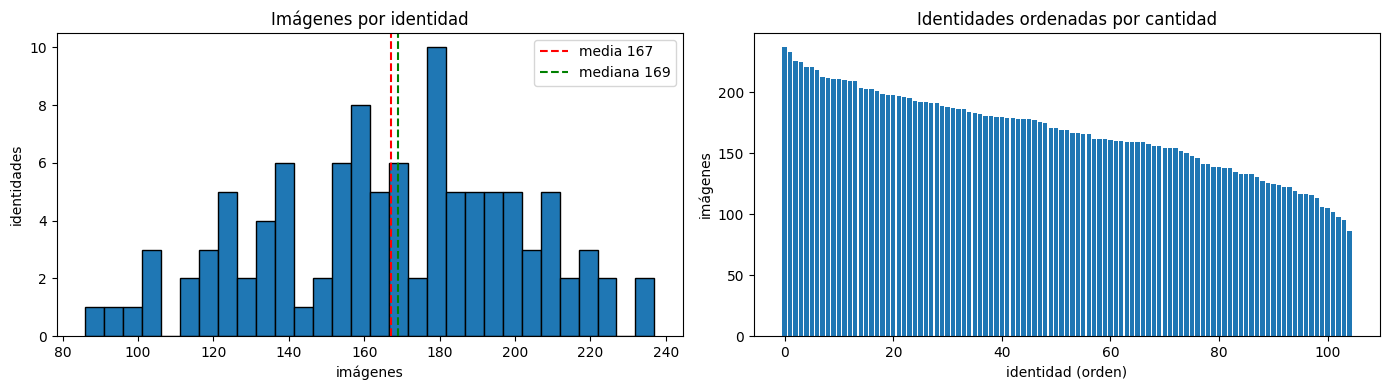

In [6]:
counts = dataset["identity"].value_counts()
stats = counts.describe()[["mean", "50%", "min", "max"]].rename({"50%": "mediana"})
print(stats.round(1).to_string())
print(f"Desbalance (máx / mín): {counts.max() / counts.min():.1f}×")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(counts, bins=30, edgecolor="black")
axes[0].axvline(counts.mean(), color="red", ls="--", label=f"media {counts.mean():.0f}")
axes[0].axvline(counts.median(), color="green", ls="--", label=f"mediana {counts.median():.0f}")
axes[0].set(title="Imágenes por identidad", xlabel="imágenes", ylabel="identidades")
axes[0].legend()
axes[1].bar(range(len(counts)), counts.values)
axes[1].set(title="Identidades ordenadas por cantidad", xlabel="identidad (orden)", ylabel="imágenes")
plt.tight_layout()
plt.show()

El enunciado sugiere un mínimo de 10 a 20 imágenes por identidad para la CNN custom. Fijamos **20**: además de entrenar, cada identidad del closed-set tiene que aportar imágenes a train, validación y test (15% + 15%), y con 20 imágenes eso son al menos 3 por split.

El desbalance es moderado. Las identidades tienen entre ~86 y ~237 imágenes (≈2,8×), con media 167 y mediana 169. Media y mediana casi iguales indican una distribución simétrica, sin identidades con muy pocas fotos. Todas superan ampliamente el mínimo de 20, así que el filtro no descarta ninguna. Al estar en el límite del criterio de 2-3×, el desbalance no justifica por sí solo técnicas de rebalanceo; en 2.6 se deja planteada la comparación con weighted sampling.

In [7]:
MIN_IMAGES_PER_IDENTITY = 20
before = dataset["identity"].nunique()
dataset = filter_min_images(dataset, MIN_IMAGES_PER_IDENTITY)
print(f"Identidades con ≥ {MIN_IMAGES_PER_IDENTITY} imágenes: {dataset['identity'].nunique()} de {before} "
      f"| imágenes: {len(dataset)}")

Identidades con ≥ 20 imágenes: 105 de 105 | imágenes: 17534


### Formatos, canales y archivos corruptos

In [8]:
dataset = inspect_files(dataset, DATASET_ROOT)
display(pd.crosstab(dataset["extension"], dataset["mode"].fillna("no abre"), margins=True))
print(f"Archivos que no abren: {(~dataset['readable']).sum()}")

mode,RGB,All
extension,,
.jpg,17534,17534
All,17534,17534


Archivos que no abren: 0


OpenCV siempre carga en **BGR de 3 canales**, aunque el archivo sea gris (`L`) o tenga transparencia (`RGBA`). Por eso todo el pipeline va a trabajar en BGR uint8 (como `cv2.imread` y como el backend) y la conversión a RGB va a ocurrir en un único lugar, justo antes del modelo.

Un archivo se considera corrupto si `PIL` no puede verificarlo o `cv2.imread` devuelve `None`. Se descarta en la limpieza (2.3).

### Resoluciones

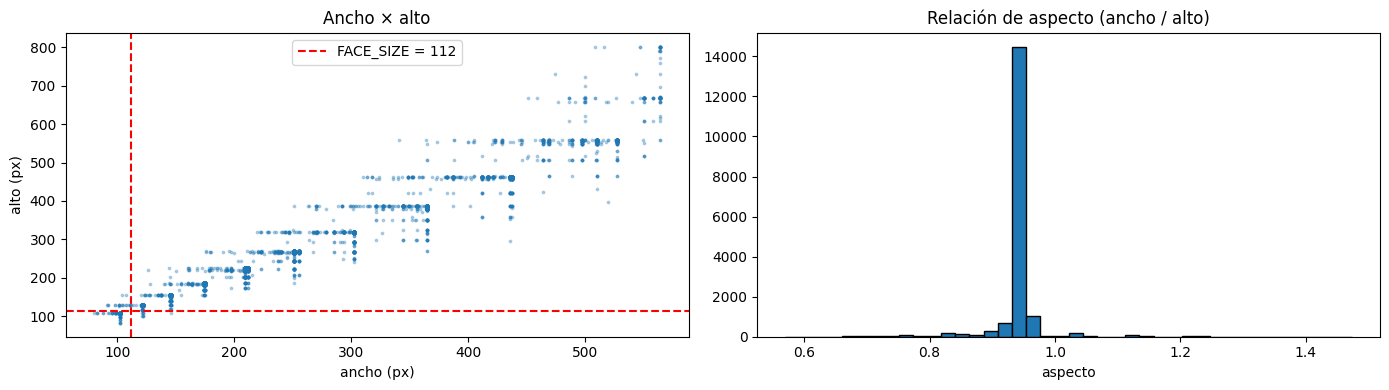

         width   height
count  17534.0  17534.0
mean     211.0    226.0
std      102.0    113.0
min       80.0     82.0
25%      122.0    129.0
50%      175.0    185.0
75%      255.0    268.0
max      564.0    802.0
Imágenes con algún lado < 112px: 2626


In [9]:
readable = dataset[dataset["readable"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(readable["width"], readable["height"], s=3, alpha=0.3)
axes[0].axvline(FACE_SIZE, color="red", ls="--")
axes[0].axhline(FACE_SIZE, color="red", ls="--", label=f"FACE_SIZE = {FACE_SIZE}")
axes[0].set(title="Ancho × alto", xlabel="ancho (px)", ylabel="alto (px)")
axes[0].legend()
axes[1].hist(readable["aspect_ratio"], bins=40, edgecolor="black")
axes[1].set(title="Relación de aspecto (ancho / alto)", xlabel="aspecto")
plt.tight_layout()
plt.show()

print(readable[["width", "height"]].describe().round(0).to_string())
small = (readable[["width", "height"]].min(axis=1) < FACE_SIZE).sum()
print(f"Imágenes con algún lado < {FACE_SIZE}px: {small}")

El tamaño que importa no es el de la imagen sino el de la **cara dentro de la imagen**: ese análisis necesita el detector y va en la sección 2.4.

### Muestra visual

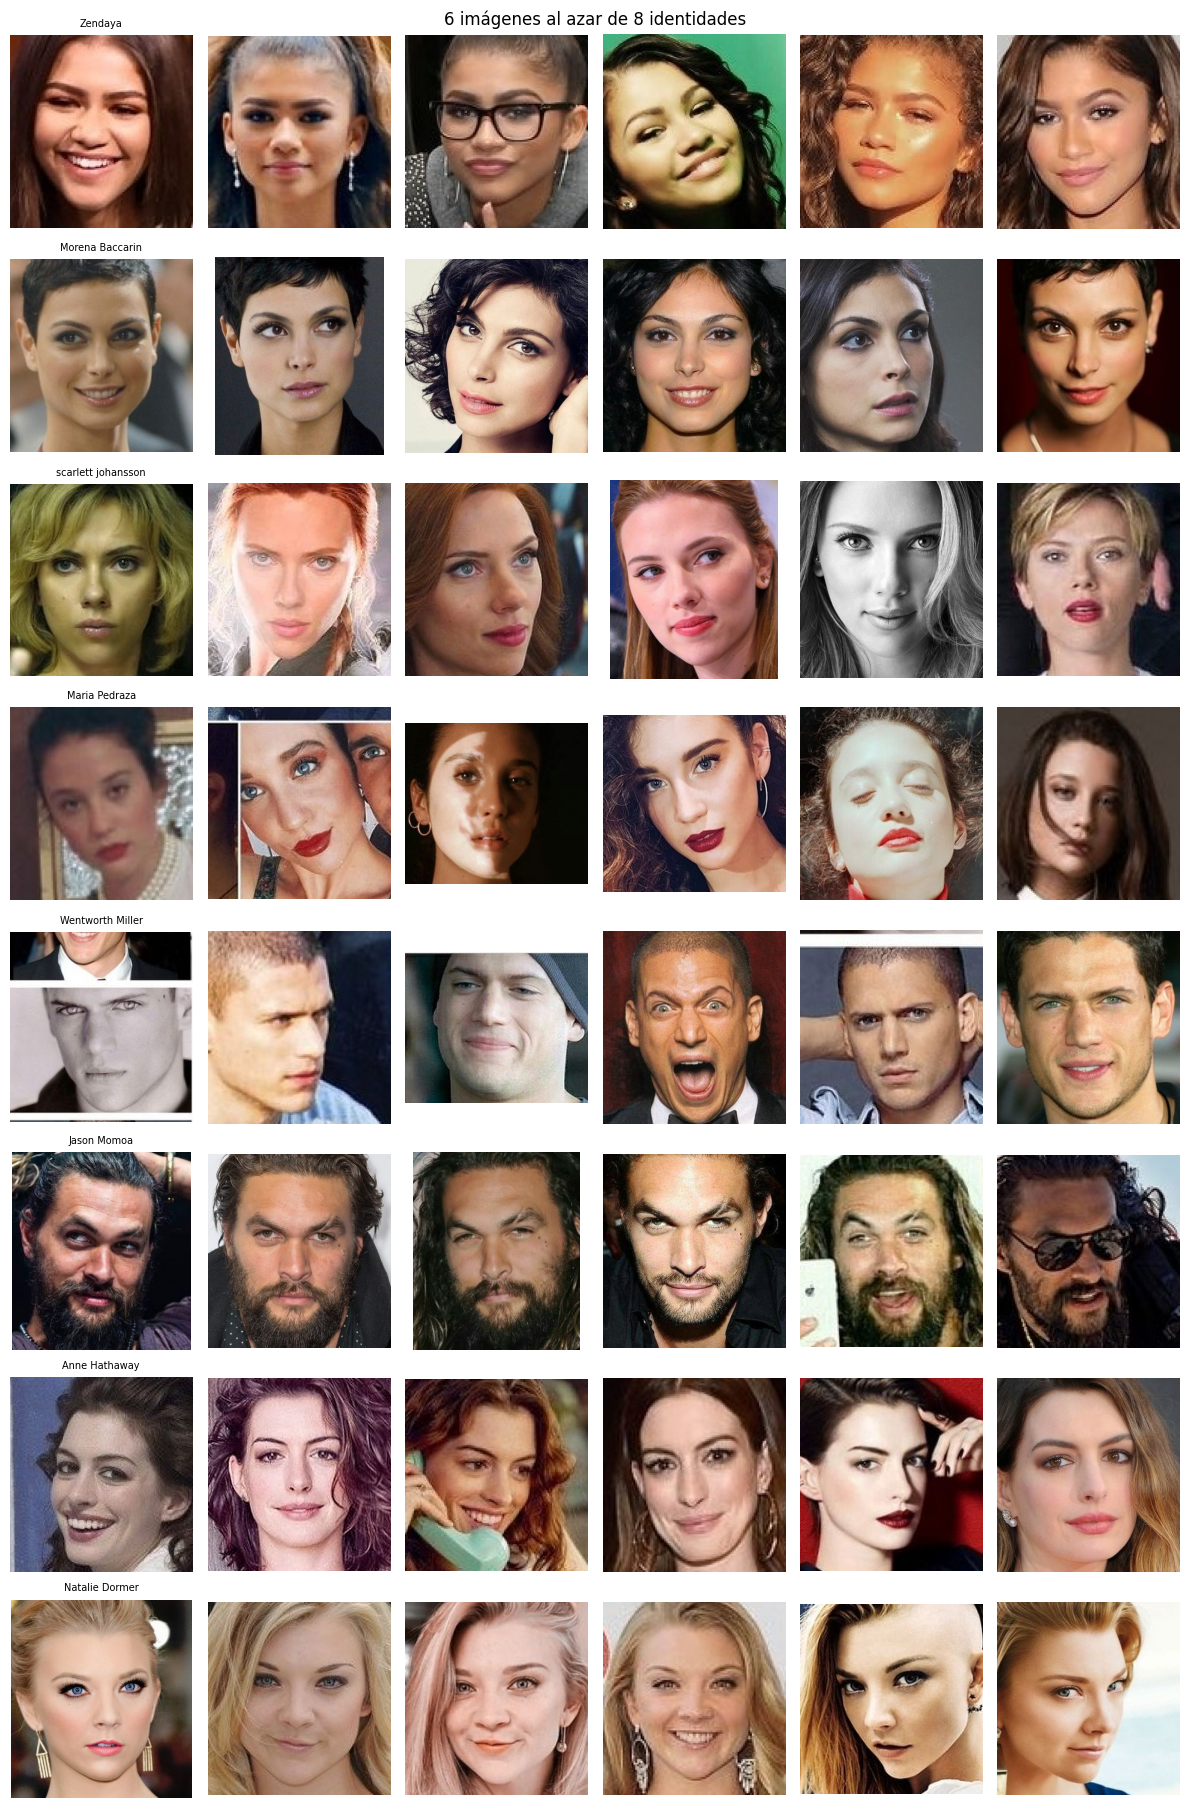

In [10]:
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(dataset["identity"].unique(), size=min(8, dataset["identity"].nunique()), replace=False)
images, titles = [], []
for identity in sample_ids:
    rows = dataset[(dataset["identity"] == identity) & dataset["readable"]].sample(6, random_state=SEED)
    images += [cv2.imread(str(DATASET_ROOT / p)) for p in rows["path"]]
    titles += [identity] + [""] * 5
show_grid(images, titles, ncols=6, size=2.0, suptitle="6 imágenes al azar de 8 identidades")

Las imágenes ya vienen recortadas a la cara (el dataset las publica como “cropped”), con un solo rostro por foto. En la muestra aparecen pocas fotos en blanco y negro (2 de 48). Al estar recortadas, el rostro ocupa casi toda la imagen, así que se espera que la regla de “cara chica” descarte poco y que la de “varias caras” casi no actúe. Lo verificamos en 2.3.

La iluminación, la pose y el blanco y negro se cuantifican sobre la cara alineada, en la sección 2.4.

## 2.4 Detección y alineación

Esta sección va antes que la limpieza (2.3) porque varias reglas de calidad necesitan el detector (sin cara, varias caras, cara chica) y el blur y la exposición se miden sobre la cara alineada.

### Detector: SCRFD de InsightFace (`det_10g.onnx`, paquete `buffalo_l`)

| Detector | Cómo funciona | Por qué sí o por qué no |
|---|---|---|
| **SCRFD / RetinaFace** (elegido) | Single-shot: una red y una pasada devuelven caja, score y 5 landmarks | Costo fijo y robusto a escala. Es el detector de InsightFace, el modelo de referencia de la parte 2, y el que va a usar la app: la consistencia entre notebook y backend sale gratis. |
| MTCNN | Cascada de 3 CNN (P-Net, R-Net, O-Net) sobre una pirámide de imágenes, con NMS entre etapas | Es el de la práctica. Costo variable (depende de cuántos candidatos sobreviven) y más lento. |
| YuNet (OpenCV) | Detector liviano con landmarks | Muy rápido, menos preciso con caras chicas o de perfil. |

- **Umbral de score:** `DET_SCORE_THRESHOLD` del `.env` (0,5), el mismo que la app.
- **Tamaño mínimo:** el detector se instancia sin filtro de tamaño (`min_face_size=0`) para poder **medir** el tamaño de las caras; el filtro se aplica después como regla de calidad (2.3) y se reporta.
- **Varias caras:** se toma como principal la de mayor área; la regla de 2.3 decide si la imagen se conserva.

### Alineación

`FaceAligner` estima una **transformación de similitud** (rotación, escala uniforme y traslación: 4 grados de libertad) que lleva los 5 landmarks a la plantilla de ArcFace, por mínimos cuadrados, y recorta a `FACE_SIZE × FACE_SIZE` (`insightface.utils.face_align.norm_crop`). Se usa similitud y no afín (6 grados de libertad) porque la afín puede estirar o cizallar la cara y alterar las proporciones que identifican a la persona.

### Imágenes ya recortadas: borde antes de detectar

Las imágenes de Pins ya vienen recortadas a la cara (2.2). SCRFD está entrenado con fotos donde la cara es una parte de la escena: si el rostro ocupa todo el cuadro, no lo encuentra. Por eso el detector acepta `pad_ratio`, que agrega un borde negro de ese tamaño relativo antes de detectar y devuelve las coordenadas en la imagen original. Se compara sobre una muestra para justificar el valor:

In [11]:
sample = dataset[dataset["readable"]].sample(300, random_state=SEED)
sample_images = [cv2.imread(str(DATASET_ROOT / p)) for p in sample["path"]]
pad_rates = {}
for pad_ratio in [0.0, 0.1, 0.25, 0.5]:
    probe = ScrfdDetector.from_model_pack(root=INSIGHTFACE_ROOT, score_threshold=DET_SCORE_THRESHOLD,
                                          input_size=DET_INPUT_SIZE, min_face_size=0, pad_ratio=pad_ratio)
    pad_rates[pad_ratio] = np.mean([len(probe.detect(img)) > 0 for img in sample_images])
display((pd.Series(pad_rates, name="% de imágenes con al menos una cara") * 100).round(1).rename_axis("pad_ratio").to_frame())

download_path: C:\Users\vlujambio.WIENER-LAB\.insightface\models\buffalo_l


100%|██████████| 281857/281857 [00:07<00:00, 39297.38KB/s]


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}


,% de imágenes con al menos una cara
pad_ratio,
0.00,10.3
0.10,78.3
0.25,100.0
0.50,100.0


Sin borde, SCRFD encuentra cara solo en el 10,3 % de la muestra: confirma que el recorte al ras le saca el contexto que necesita. Con 0,1 sube a 78,3 % y con 0,25 llega al 100 %; 0,5 no agrega nada y achica la cara relativa a la entrada del detector. Se usa `PAD_RATIO = 0.25`, el menor valor que detecta todas las imágenes de la muestra.

In [12]:
PAD_RATIO = 0.25

detector = ScrfdDetector.from_model_pack(
    root=INSIGHTFACE_ROOT,
    score_threshold=DET_SCORE_THRESHOLD,
    input_size=DET_INPUT_SIZE,
    min_face_size=0,
    pad_ratio=PAD_RATIO,
)
aligner = FaceAligner(FACE_SIZE)

FACES_CSV = PROCESSED_DIR / "faces.csv"
if FACES_CSV.exists():   
    faces = pd.read_csv(FACES_CSV)
else:
    faces = detect_and_align(dataset, DATASET_ROOT, detector, aligner, ALIGNED_DIR)
    faces.to_csv(FACES_CSV, index=False)

display(faces["n_faces"].astype("Int64").value_counts(dropna=False).rename("imágenes").to_frame().rename_axis("caras detectadas"))

Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}


Detectando:   0%|          | 0/17534 [00:00<?, ?it/s]c:\Valentin\Personales\UNR\Vision por computadora\TP_1\.venv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)
Detectando: 100%|██████████| 17534/17534 [1:42:19<00:00,  2.86it/s]     


,imágenes
caras detectadas,
1,17445
2,72
3,12
0,5


La detección sobre las 17.534 imágenes tardó 1 h 42 min en CPU (unas 2,9 imágenes por segundo). Se guarda en `data/processed/faces.csv` junto con los recortes alineados en `data/processed/aligned/`: las ejecuciones siguientes los reutilizan. Si se cambia el detector o `PAD_RATIO`, hay que borrar `faces.csv` para recalcular.

### Antes y después de la alineación

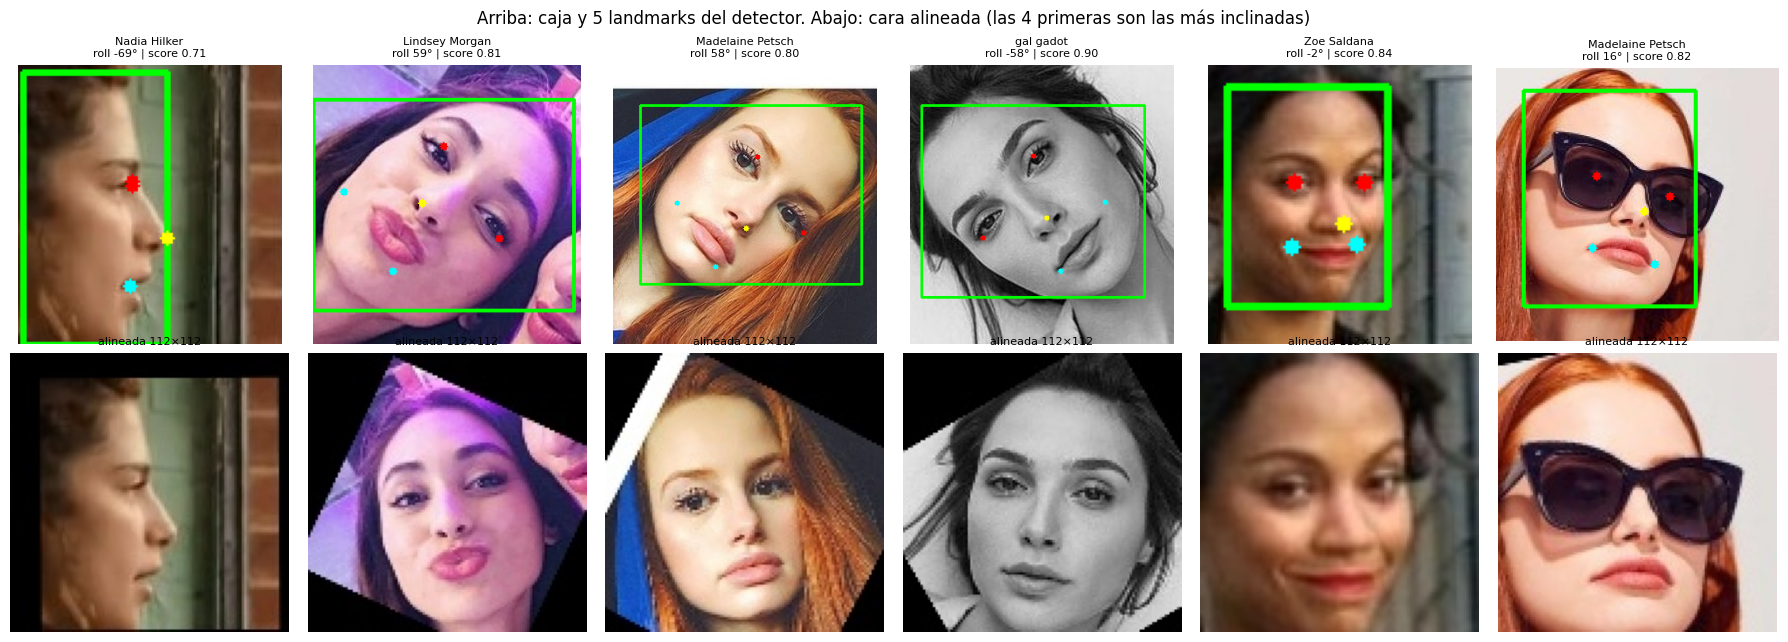

In [13]:
with_face = faces[faces["n_faces"] >= 1].copy()
with_face = with_face.join(pose_angles(with_face))
examples = pd.concat([
    with_face.reindex(with_face["roll"].abs().sort_values(ascending=False).index).head(4),
    with_face.sample(2, random_state=SEED),
])

fig, axes = plt.subplots(2, len(examples), figsize=(3 * len(examples), 6.5))
landmark_colors = [(0, 0, 255)] * 2 + [(0, 255, 255)] + [(255, 255, 0)] * 2   # ojos, nariz, boca (BGR)
for col, (_, row) in enumerate(examples.iterrows()):
    image = cv2.imread(str(DATASET_ROOT / row["path"]))
    cv2.rectangle(image, (int(row.x1), int(row.y1)), (int(row.x2), int(row.y2)), (0, 255, 0), 2)
    for (x, y), color in zip(keypoints_of(row), landmark_colors):
        cv2.circle(image, (int(x), int(y)), 3, color, -1)
    axes[0, col].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(f"{row['identity']}\nroll {row['roll']:.0f}° | score {row['det_score']:.2f}", fontsize=8)
    axes[1, col].imshow(cv2.cvtColor(load_aligned([row["aligned_path"]], ALIGNED_DIR)[0], cv2.COLOR_BGR2RGB))
    axes[1, col].set_title(f"alineada {FACE_SIZE}×{FACE_SIZE}", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Arriba: caja y 5 landmarks del detector. Abajo: cara alineada (las 4 primeras son las más inclinadas)")
plt.tight_layout()
plt.show()

### EDA de la cara: tamaño, iluminación, pose y color

Con la cara detectada se miden las variaciones que pide el EDA:
- **Tamaño de la cara:** lado menor de la caja. Una cara de 40 px llevada a 112×112 se agranda casi 3 veces y la red ve detalle inventado por la interpolación.
- **Iluminación:** brillo medio (dónde está la masa del histograma) y desvío (contraste) de la cara alineada en gris.
- **Pose:** *roll* (inclinación de la línea de los ojos) y un indicador de *yaw* (giro lateral): desplazamiento horizontal de la nariz respecto del punto medio de los ojos, dividido por la distancia entre ojos. Cerca de 0 es frontal.
- **Blanco y negro:** caras cuyos tres canales son prácticamente iguales.

Las medidas se calculan con `measure_aligned`, que recibe una lista de funciones imagen → valores. En 2.3 se le agrega la nitidez sin modificarla.

Midiendo: 100%|██████████| 17529/17529 [01:08<00:00, 256.19it/s]


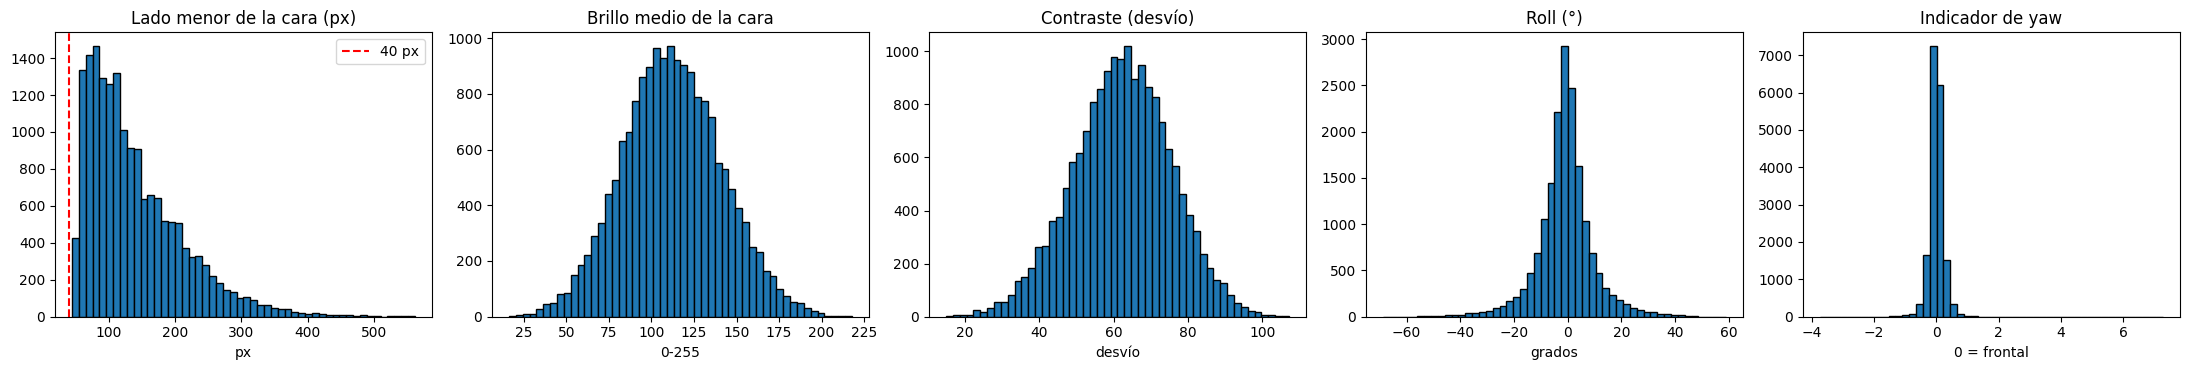

       face_min_side  brightness  contrast      roll  yaw_proxy
count       17529.00    17529.00  17529.00  17529.00   17529.00
mean          139.11      112.19     62.23     -0.97       0.00
std            72.02       29.28     13.20     10.55       0.24
min            45.00       16.30     14.95    -68.82      -3.73
1%             52.00       46.04     30.68    -33.13      -0.61
5%             59.00       64.66     39.82    -17.82      -0.34
50%           120.00      111.55     62.48     -0.87       0.00
95%           280.00      161.63     83.45     16.12       0.35
99%           369.00      181.86     91.85     30.48       0.59
max           561.00      217.77    107.09     58.98       7.28

Caras en blanco y negro: 1278 (7.3%)


In [14]:
with_face = with_face.join(measure_aligned(with_face, ALIGNED_DIR, [exposure, grayscale]))
with_face["is_grayscale"] = with_face["is_grayscale"].astype(bool)

fig, axes = plt.subplots(1, 5, figsize=(22, 3.8))
axes[0].hist(with_face["face_min_side"], bins=50, edgecolor="black")
axes[0].axvline(40, color="red", ls="--", label="40 px")
axes[0].set(title="Lado menor de la cara (px)", xlabel="px")
axes[0].legend()
axes[1].hist(with_face["brightness"], bins=50, edgecolor="black")
axes[1].set(title="Brillo medio de la cara", xlabel="0-255")
axes[2].hist(with_face["contrast"], bins=50, edgecolor="black")
axes[2].set(title="Contraste (desvío)", xlabel="desvío")
axes[3].hist(with_face["roll"], bins=50, edgecolor="black")
axes[3].set(title="Roll (°)", xlabel="grados")
axes[4].hist(with_face["yaw_proxy"], bins=50, edgecolor="black")
axes[4].set(title="Indicador de yaw", xlabel="0 = frontal")
plt.tight_layout()
plt.show()

print(with_face[["face_min_side", "brightness", "contrast", "roll", "yaw_proxy"]]
      .describe(percentiles=[.01, .05, .5, .95, .99]).round(2).to_string())
print(f"\nCaras en blanco y negro: {with_face['is_grayscale'].sum()} ({with_face['is_grayscale'].mean():.1%})")

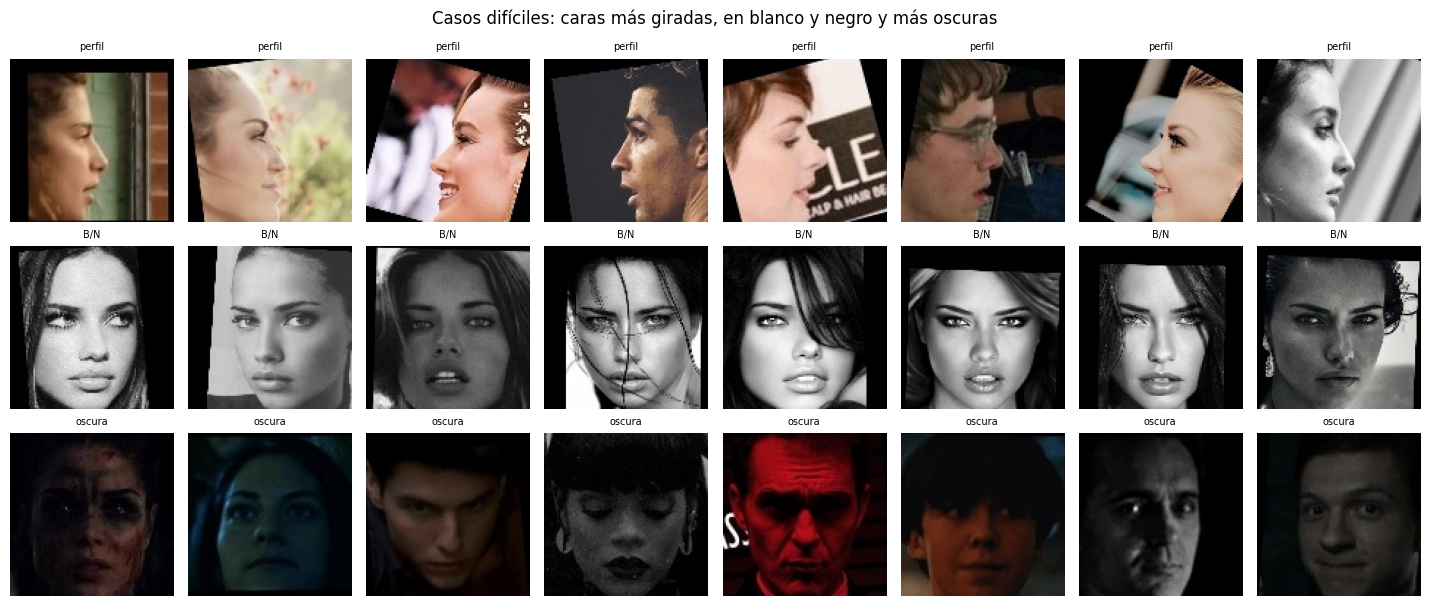

In [15]:
profiles = with_face.reindex(with_face["yaw_proxy"].abs().sort_values(ascending=False).index).head(8)
grays = with_face[with_face["is_grayscale"]].head(8)
dark = with_face.nsmallest(8, "brightness")
show_grid(
    load_aligned(pd.concat([profiles, grays, dark])["aligned_path"], ALIGNED_DIR),
    ["perfil"] * len(profiles) + ["B/N"] * len(grays) + ["oscura"] * len(dark),
    ncols=8, suptitle="Casos difíciles: caras más giradas, en blanco y negro y más oscuras",
)

**Resultado de la detección.** De 17.534 imágenes, 17.445 (99,5 %) tienen exactamente una cara, 84 tienen varias (72 con dos, 12 con tres) y 5 ninguna. En las imágenes con varias caras la principal domina: su área es en mediana 12,7 veces la de la segunda, y solo en una imagen es menos del doble. Por eso alinear la cara de mayor área es razonable, pero esas 84 imágenes tienen riesgo de etiqueta y se deciden en 2.3 junto con las 5 sin cara.

**Tamaño.** Ninguna cara queda por debajo de 40 px: la mínima mide 45 px, el percentil 1 es 52 px y la mediana 120 px. El filtro por tamaño mínimo casi no va a descartar nada en Pins; sigue siendo necesario para la app, donde las caras pueden ser chicas.

**Pose.** El dataset es mayormente frontal: el roll está entre -18° y 16° en el 90 % de las caras y el indicador de yaw entre -0,34 y 0,35. Hay una cola de perfiles y caras inclinadas (roll hasta ±69°). En perfiles extremos los landmarks fallan (en la grilla, el perfil de Nadia Hilker da roll -69° porque los dos ojos caen en el mismo lado) y el recorte alineado sale mal; los valores extremos de yaw (-3,7 y 7,3) son de ese tipo de error.

**Iluminación y color.** El brillo medio de la cara es 112 (de 0 a 255), con percentiles 1 y 99 de 46 y 182: pocas caras muy oscuras (escenas nocturnas o con luz de color, como en la grilla) y casi ninguna sobreexpuesta (máximo 218). Hay 1.278 caras en blanco y negro (7,3 %), más de lo que sugería la muestra de 2.2. En la grilla aparecen todas de Adriana Lima porque se toman las primeras filas, no porque sean todas de ella.

**Consecuencias.** Para 2.3: decidir qué hacer con las imágenes sin cara o con varias, y fijar el umbral de exposición mirando la cola oscura del histograma. Para 2.6: rotaciones chicas (±10°) alcanzan porque la alineación ya corrige el roll; conviene variar brillo y contraste, y pasar a gris una fracción baja de imágenes, ya que el 7 % del dataset ya lo está.

## 2.3 Control de calidad y limpieza

Las reglas se aplican **en orden** y cada imagen descartada se atribuye a la primera regla que falla, así la suma de descartes por regla coincide con el total. Cada regla es una clase con un único método `fails(df)` (`src/lib/dataset/quality.py`): agregar o sacar una regla no toca `QualityFilter`.

| Regla | Umbral | Cómo se eligió |
|---|---|---|
| Archivo corrupto | — | `PIL` o `cv2.imread` no pueden abrirlo (2.2). |
| Cero o varias caras | ratio de dominancia 2 | Sin cara se descarta. Con varias, se conserva la principal solo si su área es al menos el doble de la segunda; si no, no hay forma confiable de saber cuál es la persona etiquetada. |
| Cara chica | lado < 40 px | Sugerencia del enunciado. Es más exigente que `MIN_FACE_SIZE=20` de la app a propósito: para entrenar conviene ser más estricto que para aceptar en producción. |
| Borrosa | varianza del Laplaciano | Histograma y ejemplos en el límite, abajo. |
| Exposición extrema | brillo y % de píxeles saturados | Histograma de brillo de 2.4 y ejemplos, abajo. |

**Nitidez.** El Laplaciano responde a los bordes; una imagen borrosa casi no tiene bordes y la varianza de esa respuesta es baja. Se mide sobre la cara alineada de 112×112 y no sobre la imagen original: todas quedan en la misma escala y el fondo desenfocado de un retrato no cuenta. Se agrega como una medida más de `measure_aligned`, sin modificar esa función.

### Umbral de blur

In [ ]:
with_face = with_face.join(measure_aligned(with_face, ALIGNED_DIR, [sharpness]))
# Las medidas de la cara pasan a faces (NaN donde no hay cara) para que las reglas se apliquen sobre todo el dataset
faces = faces.join(with_face.drop(columns=faces.columns))

BLUR_MIN_LAPLACIAN_VAR = 30.0   # a revisar con el histograma y los ejemplos de abajo

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(np.log10(with_face["laplacian_var"].clip(lower=1)), bins=60, edgecolor="black")
ax.axvline(np.log10(BLUR_MIN_LAPLACIAN_VAR), color="red", ls="--", label=f"umbral = {BLUR_MIN_LAPLACIAN_VAR:g}")
ax.set(title="Varianza del Laplaciano sobre la cara alineada (escala log10)", xlabel="log10(var)")
ax.legend()
plt.show()
print(with_face["laplacian_var"].describe(percentiles=[.01, .02, .05, .5]).round(1).to_string())

order = with_face.sort_values("laplacian_var")
below = order[order["laplacian_var"] < BLUR_MIN_LAPLACIAN_VAR].tail(8)
above = order[order["laplacian_var"] >= BLUR_MIN_LAPLACIAN_VAR].head(8)
show_grid(
    load_aligned(pd.concat([below, above])["aligned_path"], ALIGNED_DIR),
    [f"{v:.0f} descarta" for v in below["laplacian_var"]] + [f"{v:.0f} conserva" for v in above["laplacian_var"]],
    ncols=8, suptitle="Justo debajo (se descartan) y justo encima (se conservan) del umbral de blur",
)

Criterio para validar el umbral: si las que se conservan todavía se ven borrosas, el umbral es bajo; si las que se descartan se ven nítidas, es alto.

### Umbral de exposición

In [ ]:
EXPOSURE_RULE = ExposureRule(min_brightness=40, max_brightness=215, max_clipped_fraction=0.3)   # a revisar con el histograma de brillo de 2.4

exposure_fails = with_face[EXPOSURE_RULE.fails(with_face)]
print(f"Fallan la regla de exposición: {len(exposure_fails)}")
if len(exposure_fails):
    sample = exposure_fails.sample(min(16, len(exposure_fails)), random_state=SEED)
    show_grid(load_aligned(sample["aligned_path"], ALIGNED_DIR), [f"brillo {b:.0f}" for b in sample["brightness"]],
              ncols=8, suptitle="Caras descartadas por exposición extrema")

### Resultado de las reglas de calidad

Los duplicados se agregan después como una regla más del mismo filtro, porque necesitan los embeddings.

In [ ]:
base_rules = [
    CorruptFileRule(),
    FaceCountRule(dominance_ratio=2.0),
    MinFaceSizeRule(min_side=40),
    BlurRule(min_laplacian_var=BLUR_MIN_LAPLACIAN_VAR),
    EXPOSURE_RULE,
]
checked, base_report = QualityFilter(base_rules).apply(faces)
display(base_report)
print(f"Pasan las reglas de calidad: {checked['discard_reason'].isna().sum()} de {len(checked)}")

In [ ]:
for rule in base_rules:
    discarded = checked[checked["discard_reason"] == rule.name]
    if discarded.empty or isinstance(rule, CorruptFileRule):   # un archivo corrupto no se puede mostrar
        continue
    sample = discarded.sample(min(8, len(discarded)), random_state=SEED)
    if isinstance(rule, FaceCountRule):   # sin cara no hay recorte: se muestra la imagen original
        imgs = [cv2.imread(str(DATASET_ROOT / p)) for p in sample["path"]]
        titles = [f"{n:.0f} caras" for n in sample["n_faces"]]
    else:
        imgs = load_aligned(sample["aligned_path"], ALIGNED_DIR)
        titles = list(sample["identity"])
    show_grid(imgs, titles, ncols=8, suptitle=f"Descartadas por: {rule.describe()} ({len(discarded)})")

**Pendiente (completar después de ejecutar):**
- Umbral de blur: valor final de `BLUR_MIN_LAPLACIAN_VAR` según el histograma y la grilla del límite, y por qué.
- Umbral de exposición: confirmar o ajustar `EXPOSURE_RULE` mirando las caras descartadas (en 2.4 el brillo tiene percentil 1 de 46 y máximo 218).
- Resultado: cuántas imágenes descarta cada regla y si algún ejemplo descartado se ve bien (en ese caso, ajustar el umbral y explicarlo).

### Embeddings para duplicados y clustering

Los duplicados se buscan por **similitud de embeddings**, una de las dos vías que propone el enunciado. Se eligió sobre el hash perceptual porque no agrega dependencias (`imagehash` no está en `requirements.txt`) y además detecta casi-duplicados que el hash no ve, como dos disparos seguidos de una ráfaga. Con embeddings normalizados L2, el coseno es un producto escalar y comparar todos contra todos es una multiplicación de matrices.

Se usa ArcFace (`w600k_r50.onnx` de `buffalo_l`), el mismo modelo preentrenado que se compara en la parte 2, a través de `OnnxFaceEmbedder`. La normalización de entrada vive en un solo lugar, `InputNormalization` (BGR a RGB y `(x - 127,5) / 127,5`), para que la notebook 2 y la app usen exactamente la misma. Los mismos embeddings se reutilizan en el clustering de 2.5.

In [ ]:
embedder = OnnxFaceEmbedder.from_model_pack(root=INSIGHTFACE_ROOT)

EMB_FILE = PROCESSED_DIR / "embeddings_arcface.npy"
if EMB_FILE.exists():
    face_embeddings = np.load(EMB_FILE)
else:
    face_embeddings = np.concatenate([
        embedder.embed(load_aligned(chunk, ALIGNED_DIR))
        for chunk in np.array_split(with_face["aligned_path"].to_numpy(), max(1, len(with_face) // 512))
    ])
    np.save(EMB_FILE, face_embeddings)
assert len(face_embeddings) == len(with_face), "La caché de embeddings no corresponde a faces.csv: borrarla y recalcular"

# Un embedding por fila de faces (NaN donde no hay cara): se indexa con el índice de cualquier subconjunto de faces
assert faces.index.equals(pd.RangeIndex(len(faces)))
embeddings = np.full((len(faces), embedder.dim), np.nan, dtype=np.float32)
embeddings[with_face.index.to_numpy()] = face_embeddings
print(f"Embeddings: {face_embeddings.shape}")

**Verificación.** Para confirmar que `InputNormalization` reproduce el preprocesamiento de InsightFace, se comparan los embeddings de una muestra con los del modelo de reconocimiento de `insightface` (el mismo que usa `FaceAnalysis` internamente) sobre las mismas caras alineadas.

In [ ]:
from insightface.model_zoo import get_model
from lib.vision import resolve_model_pack
from lib.vision.embedding import DEFAULT_RECOGNIZER_FILE

reference_model = get_model(str(resolve_model_pack(root=INSIGHTFACE_ROOT) / DEFAULT_RECOGNIZER_FILE),
                            providers=["CPUExecutionProvider"])
check = with_face.sample(32, random_state=SEED)
check_faces = load_aligned(check["aligned_path"], ALIGNED_DIR)
reference = reference_model.get_feat(check_faces)
reference = reference / np.linalg.norm(reference, axis=1, keepdims=True)
max_diff = np.abs(embedder.embed(check_faces) - reference).max()
print(f"Máxima diferencia contra insightface: {max_diff:.1e}")
assert max_diff < 1e-4

### Duplicados

Dos imágenes se consideran duplicadas si el coseno entre sus embeddings es al menos `DUPLICATE_THRESHOLD = 0,95`. Entre fotos distintas de una misma persona el coseno de ArcFace suele estar bastante más abajo, así que ese valor solo junta la misma foto con otro recorte, otra compresión o un disparo casi idéntico. Se buscan solo entre las imágenes que pasaron las reglas de calidad. Si a se parece a b y b a c, los tres forman un grupo (union-find) y se conserva una sola imagen por grupo.

In [ ]:
DUPLICATE_THRESHOLD = 0.95

candidates = checked[checked["discard_reason"].isna()]
pairs = similar_pairs(embeddings[candidates.index], threshold=DUPLICATE_THRESHOLD)
pairs["identity_i"] = candidates["identity"].to_numpy()[pairs["i"]]
pairs["identity_j"] = candidates["identity"].to_numpy()[pairs["j"]]
cross_identity = pairs[pairs["identity_i"] != pairs["identity_j"]]
print(f"Pares con coseno >= {DUPLICATE_THRESHOLD}: {len(pairs)} (entre identidades distintas: {len(cross_identity)})")

faces["is_duplicate"] = False
faces.loc[candidates.index[duplicates_to_drop(pairs, len(candidates))], "is_duplicate"] = True

if len(pairs):
    show = pairs.sort_values("similarity").head(8)
    imgs, titles = [], []
    for _, p in show.iterrows():
        a, b = candidates.iloc[int(p.i)], candidates.iloc[int(p.j)]
        imgs += load_aligned([a["aligned_path"], b["aligned_path"]], ALIGNED_DIR)
        titles += [f"{a['identity']}", f"sim {p.similarity:.3f}"]
    show_grid(imgs, titles, ncols=8, suptitle="Pares duplicados con menor similitud (los más dudosos)")

Se muestran los pares con **menor** similitud por encima del umbral: si esos ya son la misma foto, el umbral es seguro. Un par duplicado **entre identidades distintas** es un error de etiqueta (la misma foto en dos carpetas) y se revisa en 2.5.

### Resultado de la limpieza

Los duplicados entran como una regla más del mismo `QualityFilter`, al final, así el reporte cierra con el total. Después se vuelve a aplicar el mínimo de imágenes por identidad de 2.2, porque la limpieza puede dejar alguna identidad por debajo.

In [ ]:
quality_filter = QualityFilter(base_rules + [FlagRule(column="is_duplicate", name="duplicado")])
faces, quality_report = quality_filter.apply(faces)
display(quality_report)

kept = faces[faces["discard_reason"].isna()]
clean = filter_min_images(kept, MIN_IMAGES_PER_IDENTITY)
print(f"Imágenes conservadas: {len(kept)} de {len(faces)}")
print(f"Identidades con >= {MIN_IMAGES_PER_IDENTITY} imágenes tras la limpieza: {clean['identity'].nunique()} de {kept['identity'].nunique()} "
      f"| imágenes: {len(clean)}")

**Pendiente (completar después de ejecutar):**
- Verificación: anotar la diferencia máxima contra insightface.
- Duplicados: cuántos pares hay, cuántas imágenes se descartan y si los pares más dudosos de la grilla son realmente la misma foto (si no, subir `DUPLICATE_THRESHOLD` y explicarlo).
- Pares entre identidades distintas: listarlos; se analizan como posibles errores de etiqueta en 2.5.
- Resultado: total conservado e identidades que quedan tras volver a aplicar el mínimo de imágenes.